【Cell 1】Step 2：環境配置與路徑搜尋工具

In [2]:
import os
import re
import gc
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm

# 確認 GPU 運算裝置
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch 版本: {torch.__version__}")
print(f"CUDA 是否可用: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU 型號: {torch.cuda.get_device_name(0)}")

DATA_DIR = "dataset" if os.path.exists("dataset") else "."

def find_file(filename, base_dir=DATA_DIR):
    """自動在常見資料夾與子目錄搜尋檔案"""
    candidates = [
        filename,
        os.path.join(base_dir, filename),
        os.path.join(base_dir, "training", filename),
        os.path.join(base_dir, "tests", filename),
        os.path.join("training", filename),
        os.path.join("tests", filename),
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    matches = glob.glob(f"**/{filename}", recursive=True)
    if matches:
        return matches[0]
    raise FileNotFoundError(f"❌ 找不到檔案: {filename}")

PyTorch 版本: 2.6.0+cu124
CUDA 是否可用: True
GPU 型號: NVIDIA GeForce RTX 4060 Ti


c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


【Cell 2】SGF 解析與「視角統一」盤面張量（支援黑棋 B 與白棋 W）

In [3]:
def parse_sgf_moves(sgf_str, max_moves=80):
    """從單行 SGF 提取 (color, row, col) 落子序列"""
    if not isinstance(sgf_str, str):
        return []
    pattern = re.compile(r';([BW])\[([a-s]{2})\]')
    matches = pattern.findall(sgf_str)
    moves = []
    for color, coord in matches[:max_moves]:
        col = ord(coord[0]) - ord('a')
        row = ord(coord[1]) - ord('a')
        if 0 <= col < 19 and 0 <= row < 19:
            moves.append((color, row, col))
    return moves

def moves_to_tensor(moves, target_color='B'):
    """
    視角統一 (4 x 19 x 19)：
    - Channel 0: 待測玩家 (己方) 棋子
    - Channel 1: 對手棋子
    - Channel 2: 己方最近 6 手落子時序權重
    - Channel 3: 執色標記平面 (執黑=1.0, 執白=0.0)
    """
    board = np.zeros((4, 19, 19), dtype=np.float32)
    my_history = []
    for color, r, c in moves:
        if color == target_color:
            board[0, r, c] = 1.0
            my_history.append((r, c))
        else:
            board[1, r, c] = 1.0
    for idx, (r, c) in enumerate(my_history[-6:]):
        board[2, r, c] = (idx + 1) / 6.0
    if target_color == 'B':
        board[3, :, :] = 1.0
    return board

【Cell 3】高速預解析 Dataset 與訓練集架構（GoStyleNet）

In [5]:
class FastGoStyleDataset(Dataset):
    def __init__(self, df, player2idx, max_moves=80):
        self.labels = torch.tensor(df['player_id'].map(player2idx).values, dtype=torch.long)
        sgf_list = df['sgf_content'].tolist()
        color_list = df['color'].tolist()
        tensors = np.zeros((len(df), 4, 19, 19), dtype=np.float32)
        for i, (sgf, col) in enumerate(tqdm(zip(sgf_list, color_list), total=len(df), desc="特徵提取中", leave=False)):
            moves = parse_sgf_moves(sgf, max_moves)
            tensors[i] = moves_to_tensor(moves, target_color=col)
        self.tensors = torch.from_numpy(tensors)

    def __len__(self):
        return len(self.tensors)

    def __getitem__(self, idx):
        return self.tensors[idx], self.labels[idx]

class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(x + self.conv(x))

class GoStyleNet(nn.Module):
    def __init__(self, num_classes, emb_dim=256, num_res_blocks=3):
        super().__init__()
        self.in_conv = nn.Sequential(
            nn.Conv2d(4, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        stage1 = [ResidualBlock(64) for _ in range(num_res_blocks)]
        downsample = [
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        ]
        stage2 = [ResidualBlock(128) for _ in range(num_res_blocks)]
        self.backbone = nn.Sequential(*(stage1 + downsample + stage2))
        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.max_pool = nn.AdaptiveMaxPool2d((1, 1))
        self.fc = nn.Sequential(
            nn.Linear(256, emb_dim),
            nn.BatchNorm1d(emb_dim)
        )
        self.classifier = nn.Linear(emb_dim, num_classes, bias=False)

    def extract_embedding(self, x):
        x = self.in_conv(x)
        x = self.backbone(x)
        feat = torch.cat([
            torch.flatten(self.avg_pool(x), 1),
            torch.flatten(self.max_pool(x), 1)
        ], dim=1)
        emb = self.fc(feat)
        return F.normalize(emb, p=2, dim=1)

    def forward(self, x):
        emb = self.extract_embedding(x)
        w = F.normalize(self.classifier.weight, p=2, dim=1)
        logits = F.linear(emb, w) * 20.0
        return logits, emb

【Cell 4】通用訓練管線與四份測試集推論函數（涵蓋 1,600 題）

In [6]:
def load_and_split_data(samples_per_rank=None):
    """讀取 10 個等級訓練資料並切分 Train / Val[cite: 5, 7]"""
    rank_files = [
        "train_D.csv", "train_C.csv", "train_B.csv", "train_A.csv",
        "train_1D.csv", "train_2D.csv", "train_3D.csv",
        "train_4D.csv", "train_5D.csv", "train_6D.csv"
    ]
    dfs = []
    for fname in rank_files:
        fpath = find_file(fname)
        df_rank = pd.read_csv(fpath, usecols=['player_id', 'color', 'sgf_content'])
        if samples_per_rank is not None and len(df_rank) > samples_per_rank:
            df_rank = df_rank.sample(n=samples_per_rank, random_state=42)
        dfs.append(df_rank)
        
    all_df = pd.concat(dfs, ignore_index=True)
    counts = all_df['player_id'].value_counts()
    valid_players = counts[counts >= 3].index
    all_df = all_df[all_df['player_id'].isin(valid_players)].reset_index(drop=True)
    
    unique_players = all_df['player_id'].unique()
    player2idx = {p: i for i, p in enumerate(unique_players)}
    
    val_indices = all_df.groupby('player_id').sample(n=1, random_state=42).index
    val_df = all_df.loc[val_indices].reset_index(drop=True)
    train_df = all_df.drop(val_indices).reset_index(drop=True)
    print(f"資料準備完成 -> 訓練集: {len(train_df)} 盤 | 驗證集: {len(val_df)} 盤 | 玩家數: {len(player2idx)}")
    return train_df, val_df, player2idx

def train_pipeline(samples_per_rank, epochs, batch_size, lr, max_moves, num_res_blocks, save_model_path, curve_save_path):
    """訓練模型、記錄學習曲線並保存 best_model.pth[cite: 5]"""
    train_df, val_df, player2idx = load_and_split_data(samples_per_rank=samples_per_rank)
    train_dataset = FastGoStyleDataset(train_df, player2idx, max_moves=max_moves)
    val_dataset = FastGoStyleDataset(val_df, player2idx, max_moves=max_moves)
    del train_df, val_df
    gc.collect()
    
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
    
    model = GoStyleNet(num_classes=len(player2idx), emb_dim=256, num_res_blocks=num_res_blocks).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None
    
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = -1.0
    
    for epoch in range(epochs):
        model.train()
        t_loss, t_correct, t_total = 0.0, 0, 0
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                logits, _ = model(x)
                loss = criterion(logits, y)
            if scaler:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()
            t_loss += loss.item() * len(y)
            t_correct += (logits.argmax(dim=1) == y).sum().item()
            t_total += len(y)
            pbar.set_postfix(loss=f"{t_loss/t_total:.4f}", acc=f"{t_correct/t_total:.4f}")
        scheduler.step()
        
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                logits, _ = model(x)
                loss = criterion(logits, y)
                v_loss += loss.item() * len(y)
                v_correct += (logits.argmax(dim=1) == y).sum().item()
                v_total += len(y)
                
        ep_t_loss, ep_t_acc = t_loss / t_total, t_correct / t_total
        ep_v_loss, ep_v_acc = v_loss / v_total, v_correct / v_total
        history["train_loss"].append(ep_t_loss)
        history["train_acc"].append(ep_t_acc)
        history["val_loss"].append(ep_v_loss)
        history["val_acc"].append(ep_v_acc)
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {ep_t_loss:.4f}, Acc: {ep_t_acc:.4f} | Val Loss: {ep_v_loss:.4f}, Acc: {ep_v_acc:.4f}")
        
        if ep_v_acc >= best_val_acc:
            best_val_acc = ep_v_acc
            torch.save({
                "model_state_dict": model.state_dict(),
                "num_classes": len(player2idx),
                "max_moves": max_moves,
                "num_res_blocks": num_res_blocks
            }, save_model_path)
            
    if epochs > 1:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        ep_range = range(1, epochs + 1)
        axes[0].plot(ep_range, history["train_loss"], label="Train Loss", marker='o')
        axes[0].plot(ep_range, history["val_loss"], label="Val Loss", marker='s')
        axes[0].set_title("Training & Validation Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].legend()
        axes[0].grid(True)
        
        axes[1].plot(ep_range, history["train_acc"], label="Train Acc", marker='o')
        axes[1].plot(ep_range, history["val_acc"], label="Val Acc", marker='s')
        axes[1].set_title("Training & Validation Accuracy")
        axes[1].set_xlabel("Epoch")
        axes[1].legend()
        axes[1].grid(True)
        
        plt.tight_layout()
        plt.savefig(curve_save_path, dpi=150)
        plt.show()
        print(f"📊 訓練曲線已儲存至 {curve_save_path}")
    return history

@torch.no_grad()
def extract_game_embeddings(model, sgf_list, color_list, max_moves=80, batch_size=512):
    model.eval()
    tensors = np.zeros((len(sgf_list), 4, 19, 19), dtype=np.float32)
    for i, (sgf, col) in enumerate(zip(sgf_list, color_list)):
        moves = parse_sgf_moves(sgf, max_moves=max_moves)
        tensors[i] = moves_to_tensor(moves, target_color=col)
    loader = DataLoader(torch.from_numpy(tensors), batch_size=batch_size, shuffle=False)
    embs = []
    for batch in loader:
        embs.append(model.extract_embedding(batch.to(device)).cpu().numpy())
    return np.vstack(embs)

def aggregate_embeddings(embs, method="mean", move_counts=None):
    if method == "weighted" and move_counts is not None:
        # 依據該盤實際有效落子手數加權（手數越多，棋風資訊越完整，權重越高）
        weights = np.array(move_counts, dtype=np.float32).reshape(-1, 1)
        weights = np.maximum(weights, 1.0)  # 避免 0 手除以零
        proto = np.sum(embs * weights, axis=0) / np.sum(weights)
    else:
        proto = np.mean(embs, axis=0)
    return proto / (np.linalg.norm(proto) + 1e-8)

def run_inference_and_save(checkpoint_path, output_csv_path, agg_method="mean"):
    """載入權重並對四份測試集 (pub, priv, pub2, priv2) 推論，輸出 1,600 列結果"""
    ckpt = torch.load(checkpoint_path, map_location=device)
    model = GoStyleNet(
        num_classes=ckpt["num_classes"],
        emb_dim=256,
        num_res_blocks=ckpt["num_res_blocks"]
    ).to(device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    max_moves = ckpt["max_moves"]
    
    tasks = [
        ("player_identification_candidates_public.csv", "player_identification_test_public.csv"),
        ("player_identification_candidates_private.csv", "player_identification_test_private.csv"),
        ("player_identification_candidates2_public.csv", "player_identification_test2_public.csv"),
        ("player_identification_candidates2_private.csv", "player_identification_test2_private.csv"),
    ]
    
    all_subs = []
    for cand_file, test_file in tasks:
        df_cand = pd.read_csv(find_file(cand_file))
        cand_sgfs = df_cand['sgf_content'].tolist()
        cand_moves_len = [len(parse_sgf_moves(s, max_moves=max_moves)) for s in cand_sgfs]
        cand_embs = extract_game_embeddings(model, cand_sgfs, df_cand['color'].tolist(), max_moves=max_moves)
        
        df_cand['emb'] = list(cand_embs)
        df_cand['m_len'] = cand_moves_len
        
        cand_dict = {
            pid: aggregate_embeddings(np.vstack(g['emb'].values), method=agg_method, move_counts=g['m_len'].values)
            for pid, g in df_cand.groupby('player_id')
        }
        cand_ids = list(cand_dict.keys())
        cand_matrix = np.vstack([cand_dict[pid] for pid in cand_ids])
        
        df_test = pd.read_csv(find_file(test_file))
        results = []
        for _, row in tqdm(df_test.iterrows(), total=len(df_test), desc=f"推論 {test_file}", leave=False):
            qid = row['question_id']
            num_games = int(row['num_games'])
            sgfs = [row[f'sgf_{i}'] for i in range(1, num_games + 1) if pd.notna(row.get(f'sgf_{i}'))]
            colors = [row.get(f'color_{i}', 'B') if pd.notna(row.get(f'color_{i}')) else 'B' for i in range(1, num_games + 1) if pd.notna(row.get(f'sgf_{i}'))]
            q_moves_len = [len(parse_sgf_moves(s, max_moves=max_moves)) for s in sgfs]
            
            q_embs = extract_game_embeddings(model, sgfs, colors, max_moves=max_moves)
            q_proto = aggregate_embeddings(q_embs, method=agg_method, move_counts=q_moves_len).reshape(1, -1)
            
            sims = cosine_similarity(q_proto, cand_matrix)[0]
            top5 = [cand_ids[idx] for idx in np.argsort(sims)[::-1][:5]]
            results.append({'question_id': qid, 'top_1': top5[0], 'top_2': top5[1], 'top_3': top5[2], 'top_4': top5[3], 'top_5': top5[4]})
        all_subs.append(pd.DataFrame(results))
        
    df_final = pd.concat(all_subs, ignore_index=True)[['question_id', 'top_1', 'top_2', 'top_3', 'top_4', 'top_5']]
    df_final.to_csv(output_csv_path, index=False, encoding="utf-8")
    print(f"✅ 已產出提交檔: {output_csv_path} (共 {len(df_final)} 列)")
    return df_final 

【Cell 5】Step 3 專屬執行區：小規模試跑驗證（1,000 盤/等級，1 Epoch）

In [10]:
print("=== [Step 3] 開始執行小規模試跑 (1,000 盤/等級, 1 Epoch) ===")
_ = train_pipeline(
    samples_per_rank=1000,
    epochs=1,
    batch_size=256,
    lr=1e-3,
    max_moves=80,
    num_res_blocks=3,
    save_model_path="trial_model.pth",
    curve_save_path="trial_curves.png"
)

# 試跑端到端推論驗證[cite: 5]
trial_sub = run_inference_and_save(
    checkpoint_path="trial_model.pth",
    output_csv_path="trial_submission_player.csv",
    agg_method="mean"
)
print("🎉 [Step 3] 端到端試跑成功！請繼續執行下一個 Cell 進行 Step 4 全量訓練。")

=== [Step 3] 開始執行小規模試跑 (1,000 盤/等級, 1 Epoch) ===
資料準備完成 -> 訓練集: 5279 盤 | 驗證集: 1296 盤 | 玩家數: 1296


Epoch 1/1 [Train]: 100%|██████████| 21/21 [00:00<00:00, 44.97it/s, acc=0.0015, loss=7.5851]


Epoch 1/1 | Train Loss: 7.5851, Acc: 0.0015 | Val Loss: 7.6094, Acc: 0.0008


✅ 已產出提交檔: trial_submission_player.csv (共 1600 列)
🎉 [Step 3] 端到端試跑成功！請繼續執行下一個 Cell 進行 Step 4 全量訓練。


【Cell 6】Step 4 & Step 5 專屬執行區：全量資料訓練、儲存學習曲線與正式提交檔

=== [Step 4] 開始全量資料訓練 (10 個等級全量 100 萬盤, 8 Epochs) ===
資料準備完成 -> 訓練集: 991986 盤 | 驗證集: 7997 盤 | 玩家數: 7997


Epoch 1/8 [Train]: 100%|██████████| 1938/1938 [01:30<00:00, 21.49it/s, acc=0.0157, loss=8.1264]


Epoch 1/8 | Train Loss: 8.1264, Acc: 0.0157 | Val Loss: 8.7108, Acc: 0.0098


Epoch 2/8 [Train]: 100%|██████████| 1938/1938 [01:29<00:00, 21.57it/s, acc=0.0704, loss=6.9830]


Epoch 2/8 | Train Loss: 6.9830, Acc: 0.0704 | Val Loss: 8.2317, Acc: 0.0249


Epoch 3/8 [Train]: 100%|██████████| 1938/1938 [01:30<00:00, 21.32it/s, acc=0.1037, loss=6.5443]


... (7 outputs left out)

Epoch 7/8 [Train]: 100%|██████████| 1938/1938 [01:31<00:00, 21.28it/s, acc=0.1756, loss=5.7600]


Epoch 7/8 | Train Loss: 5.7600, Acc: 0.1756 | Val Loss: 7.7618, Acc: 0.0481


Epoch 8/8 [Train]: 100%|██████████| 1938/1938 [01:31<00:00, 21.28it/s, acc=0.1855, loss=5.6721]


Epoch 8/8 | Train Loss: 5.6721, Acc: 0.1855 | Val Loss: 7.7483, Acc: 0.0490


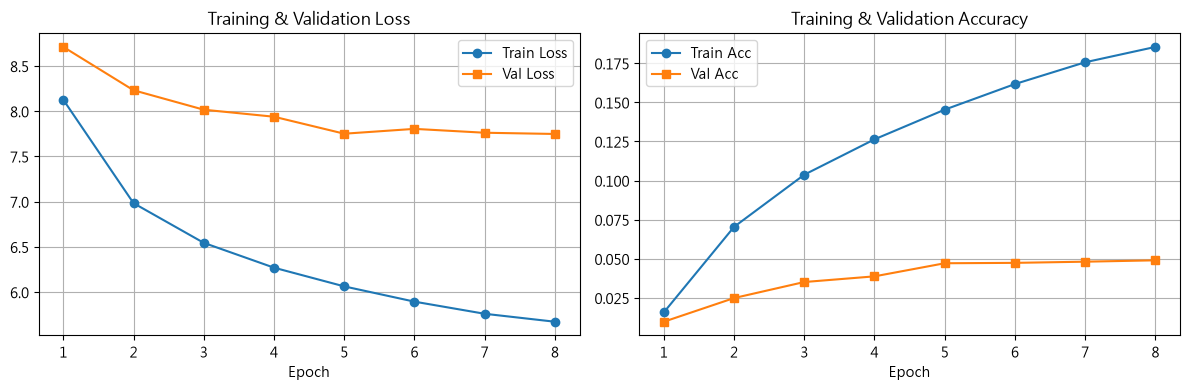

📊 訓練曲線已儲存至 full_training_curves.png

=== [Step 5] 使用 best_model.pth 產出正式提交檔 submission_player.csv ===


✅ 已產出提交檔: submission_player.csv (共 1600 列)


In [10]:
print("=== [Step 4] 開始全量資料訓練 (10 個等級全量 100 萬盤, 8 Epochs) ===")
full_history = train_pipeline(
    samples_per_rank=None,      # None = 讀取全量 100 萬盤資料[cite: 5, 7]
    epochs=8,
    batch_size=512,
    lr=1e-3,
    max_moves=80,
    num_res_blocks=3,
    save_model_path="best_model.pth",
    curve_save_path="full_training_curves.png"
)

print("\n=== [Step 5] 使用 best_model.pth 產出正式提交檔 submission_player.csv ===")
submission_df = run_inference_and_save(
    checkpoint_path="best_model.pth",
    output_csv_path="submission_player.csv",
    agg_method="mean"
)

【Cell 7】提交檔案規格驗證（1,600 題、四種前綴與候選庫值域檢查）

In [7]:
def verify_submission(sub_path="submission_player.csv"):
    df = pd.read_csv(sub_path)
    assert len(df) == 1600, f"❌ 總題數錯誤！應為 1,600 題，實際為 {len(df)} 題"
    expected_cols = ['question_id', 'top_1', 'top_2', 'top_3', 'top_4', 'top_5']
    assert list(df.columns) == expected_cols, f"❌ 欄位不符: {list(df.columns)}"
    assert not df.isnull().any().any(), "❌ 包含空值 (NaN)！"
    assert df['question_id'].nunique() == 1600, "❌ question_id 重複！"
    
    cand_pools = {
        "pub": set(pd.read_csv(find_file("player_identification_candidates_public.csv"))['player_id'].unique()),
        "priv": set(pd.read_csv(find_file("player_identification_candidates_private.csv"))['player_id'].unique()),
        "pub2": set(pd.read_csv(find_file("player_identification_candidates2_public.csv"))['player_id'].unique()),
        "priv2": set(pd.read_csv(find_file("player_identification_candidates2_private.csv"))['player_id'].unique()),
    }
    
    for idx, row in df.iterrows():
        qid = row['question_id']
        prefix = qid.split('_')[0]
        assert prefix in cand_pools, f"❌ 未知前綴: {qid}"
        preds = [row['top_1'], row['top_2'], row['top_3'], row['top_4'], row['top_5']]
        assert len(set(preds)) == 5, f"❌ 第 {idx} 列 ({qid}) Top-5 有重複！"
        valid_pool = cand_pools[prefix]
        for p in preds:
            assert p.startswith(prefix + "_"), f"❌ 第 {idx} 列 ({qid}) 前綴不一致: {p}"
            assert p in valid_pool, f"❌ 第 {idx} 列 ({qid}) 的 {p} 不在對應候選庫！"
            
    print(f"✅ '{sub_path}' 1,600 題格式、前綴、值域檢核全數通過！")

verify_submission("submission_player.csv")

✅ 'submission_player.csv' 1,600 題格式、前綴、值域檢核全數通過！


【Cell 8】Step 7 專屬執行區：單一變因實驗（One Small Change）

=== [Step 7] 開始執行單一變因訓練實驗 (lr=5e-4, 8 Epochs) ===
資料準備完成 -> 訓練集: 991986 盤 | 驗證集: 7997 盤 | 玩家數: 7997


Epoch 1/8 [Train]: 100%|██████████| 1938/1938 [01:31<00:00, 21.08it/s, acc=0.0124, loss=8.2109]


Epoch 1/8 | Train Loss: 8.2109, Acc: 0.0124 | Val Loss: 8.9655, Acc: 0.0065


Epoch 2/8 [Train]: 100%|██████████| 1938/1938 [01:31<00:00, 21.24it/s, acc=0.0607, loss=7.0984]


Epoch 2/8 | Train Loss: 7.0984, Acc: 0.0607 | Val Loss: 8.4807, Acc: 0.0178


Epoch 3/8 [Train]: 100%|██████████| 1938/1938 [01:31<00:00, 21.28it/s, acc=0.0952, loss=6.6310]


... (7 outputs left out)

Epoch 7/8 [Train]: 100%|██████████| 1938/1938 [01:31<00:00, 21.26it/s, acc=0.1668, loss=5.8395]


Epoch 7/8 | Train Loss: 5.8395, Acc: 0.1668 | Val Loss: 7.8242, Acc: 0.0438


Epoch 8/8 [Train]: 100%|██████████| 1938/1938 [01:31<00:00, 21.24it/s, acc=0.1757, loss=5.7566]


Epoch 8/8 | Train Loss: 5.7566, Acc: 0.1757 | Val Loss: 7.8154, Acc: 0.0441


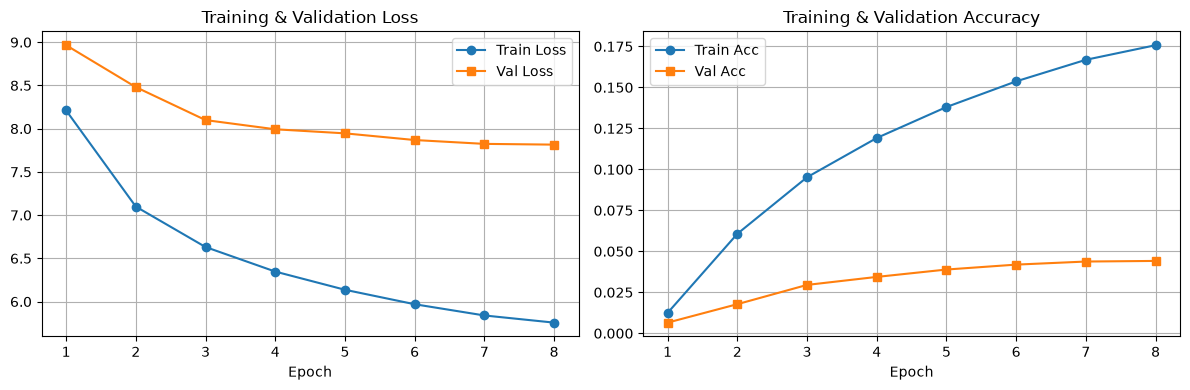

📊 訓練曲線已儲存至 exp1_training_curves.png


✅ 已產出提交檔: submission_player_exp1.csv (共 1600 列)
✅ 'submission_player_exp1.csv' 1,600 題格式、前綴、值域檢核全數通過！
🎉 [Step 7] 實驗訓練與提交檔生成完成！


In [8]:
# === [Step 7] 單一變因實驗 (One Small Change)：僅將學習率 lr 由 1e-3 改為 5e-4 ===
print("=== [Step 7] 開始執行單一變因訓練實驗 (lr=5e-4, 8 Epochs) ===")
exp_history = train_pipeline(
    samples_per_rank=None,      # 維持全量資料不變
    epochs=8,                   # 維持 8 Epochs 不變
    batch_size=512,             # 維持 Batch Size 不變
    lr=5e-4,                    # <-- 唯一更改的單一變因 (1e-3 -> 5e-4)
    max_moves=80,               # 維持前 80 手不變
    num_res_blocks=3,           # 維持殘差層數不變
    save_model_path="best_model_exp1.pth",
    curve_save_path="exp1_training_curves.png"
)

# 使用實驗最佳權重產出提交檔並驗證
exp_submission_df = run_inference_and_save(
    checkpoint_path="best_model_exp1.pth",
    output_csv_path="submission_player_exp1.csv",
    agg_method="mean"
)

verify_submission("submission_player_exp1.csv")
print("🎉 [Step 7] 實驗訓練與提交檔生成完成！")

【Cell 9】Small Change 前後差異比較圖（推論結果與指標對照）

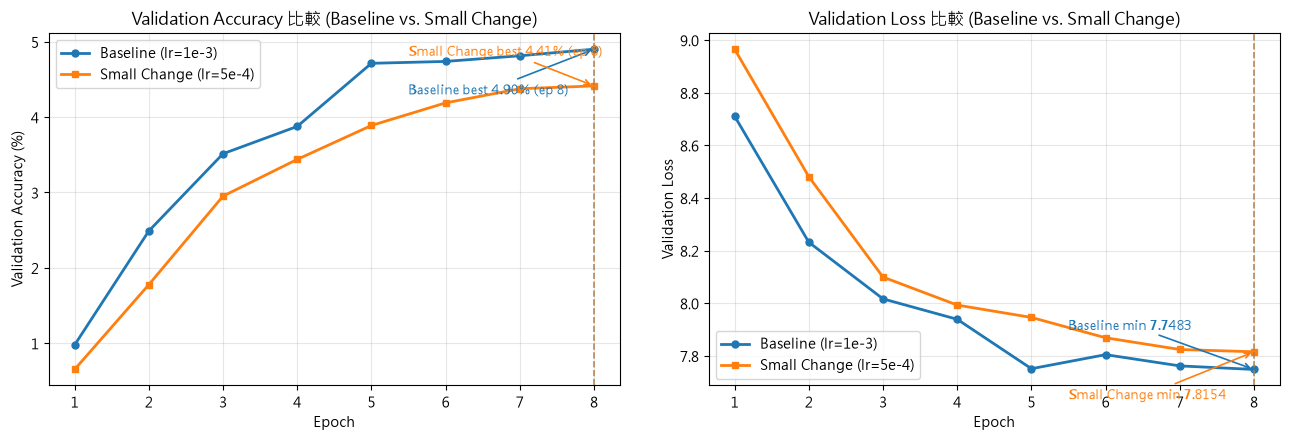

📊 雙模型驗證指標比較圖已儲存為 small_change_val_comparison.png
Baseline Best Val Acc: 4.90% (Epoch 8) | Min Val Loss: 7.7483
Small Change Best Val Acc: 4.41% (Epoch 8) | Min Val Loss: 7.8154


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 設定字體避免中文亂碼
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# 將 Accuracy 轉為百分比 (%) 以對齊參考圖格式
base_val_acc = [v * 100 for v in full_history["val_acc"]]
exp_val_acc  = [v * 100 for v in exp_history["val_acc"]]

base_val_loss = full_history["val_loss"]
exp_val_loss  = exp_history["val_loss"]

epochs = np.arange(1, len(base_val_acc) + 1)

# 找出各自最佳的 Epoch 索引
best_base_ep = int(np.argmax(base_val_acc)) + 1
best_base_acc = max(base_val_acc)

best_exp_ep = int(np.argmax(exp_val_acc)) + 1
best_exp_acc = max(exp_val_acc)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- 左圖：Validation Accuracy (%) 比較 ---
axes[0].plot(epochs, base_val_acc, marker='o', ms=5, lw=2, color='#1f77b4', label='Baseline (lr=1e-3)')
axes[0].plot(epochs, exp_val_acc,  marker='s', ms=5, lw=2, color='#ff7f0e', label='Small Change (lr=5e-4)')

# 垂直虛線與箭頭標註各自最佳點（仿照參考圖風格）
axes[0].axvline(best_base_ep, ls='--', c='#1f77b4', alpha=0.6, lw=1.2)
axes[0].annotate(
    f'Baseline best {best_base_acc:.2f}% (ep {best_base_ep})',
    xy=(best_base_ep, best_base_acc),
    xytext=(max(1, best_base_ep - 2.5), best_base_acc - 0.6),
    arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.2),
    fontsize=9.5, color='#1f77b4', fontweight='bold'
)

axes[0].axvline(best_exp_ep, ls='--', c='#ff7f0e', alpha=0.6, lw=1.2)
axes[0].annotate(
    f'Small Change best {best_exp_acc:.2f}% (ep {best_exp_ep})',
    xy=(best_exp_ep, best_exp_acc),
    xytext=(max(1, best_exp_ep - 2.5), best_exp_acc + 0.4),
    arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=1.2),
    fontsize=9.5, color='#ff7f0e', fontweight='bold'
)

axes[0].set_title('Validation Accuracy 比較 (Baseline vs. Small Change)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation Accuracy (%)')
axes[0].set_xticks(epochs)
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- 右圖：Validation Loss 比較 ---
best_base_loss_ep = int(np.argmin(base_val_loss)) + 1
best_base_loss = min(base_val_loss)

best_exp_loss_ep = int(np.argmin(exp_val_loss)) + 1
best_exp_loss = min(exp_val_loss)

axes[1].plot(epochs, base_val_loss, marker='o', ms=5, lw=2, color='#1f77b4', label='Baseline (lr=1e-3)')
axes[1].plot(epochs, exp_val_loss,  marker='s', ms=5, lw=2, color='#ff7f0e', label='Small Change (lr=5e-4)')

axes[1].axvline(best_base_loss_ep, ls='--', c='#1f77b4', alpha=0.6, lw=1.2)
axes[1].annotate(
    f'Baseline min {best_base_loss:.4f}',
    xy=(best_base_loss_ep, best_base_loss),
    xytext=(max(1, best_base_loss_ep - 2.5), best_base_loss + 0.15),
    arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.2),
    fontsize=9.5, color='#1f77b4', fontweight='bold'
)

axes[1].axvline(best_exp_loss_ep, ls='--', c='#ff7f0e', alpha=0.6, lw=1.2)
axes[1].annotate(
    f'Small Change min {best_exp_loss:.4f}',
    xy=(best_exp_loss_ep, best_exp_loss),
    xytext=(max(1, best_exp_loss_ep - 2.5), best_exp_loss - 0.18),
    arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=1.2),
    fontsize=9.5, color='#ff7f0e', fontweight='bold'
)

axes[1].set_title('Validation Loss 比較 (Baseline vs. Small Change)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Loss')
axes[1].set_xticks(epochs)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("small_change_val_comparison.png", dpi=150)
plt.show()

print(f"📊 雙模型驗證指標比較圖已儲存為 small_change_val_comparison.png")
print(f"Baseline Best Val Acc: {best_base_acc:.2f}% (Epoch {best_base_ep}) | Min Val Loss: {best_base_loss:.4f}")
print(f"Small Change Best Val Acc: {best_exp_acc:.2f}% (Epoch {best_exp_ep}) | Min Val Loss: {best_exp_loss:.4f}")